In [4]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import seaborn as sns

mnist = fetch_openml('Fashion-MNIST', version=1, as_frame=False)
X, y = mnist.data, mnist.target.astype(int)

1)Data Exploration
    1.4)Function to plot random images for each class

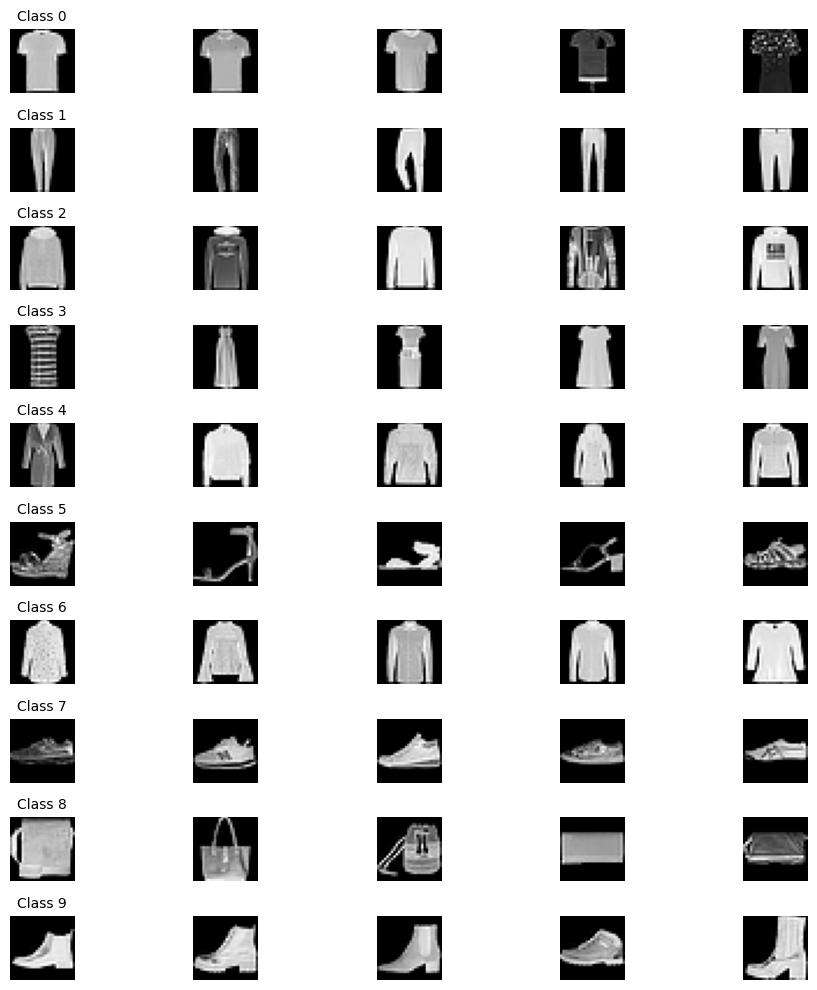

In [6]:
def plot_images_by_class(X, y, images_per_class=5):
    classes = np.unique(y)  # Get all digit classes (0–9)
    fig, axes = plt.subplots(len(classes), images_per_class, figsize=(10, 10))

    for cls_idx, cls in enumerate(classes):
        # Select indices of images for the current class
        cls_indices = np.where(y == cls)[0]
        random_indices = np.random.choice(cls_indices, images_per_class, replace=False)

        for img_idx, rand_idx in enumerate(random_indices):
            ax = axes[cls_idx, img_idx]
            ax.imshow(X[rand_idx].reshape(28, 28), cmap='gray')
            ax.axis('off')
            if img_idx == 0:
                ax.set_title(f"Class {cls}", fontsize=10)
    plt.tight_layout()
    plt.show()

plot_images_by_class(X, y, images_per_class=5)

    1.5)Define class labels for Fashion-MNIST

Frequency of each class:
T-shirt/top: 7000 samples
Trouser: 7000 samples
Pullover: 7000 samples
Dress: 7000 samples
Coat: 7000 samples
Sandal: 7000 samples
Shirt: 7000 samples
Sneaker: 7000 samples
Bag: 7000 samples
Ankle Boot: 7000 samples


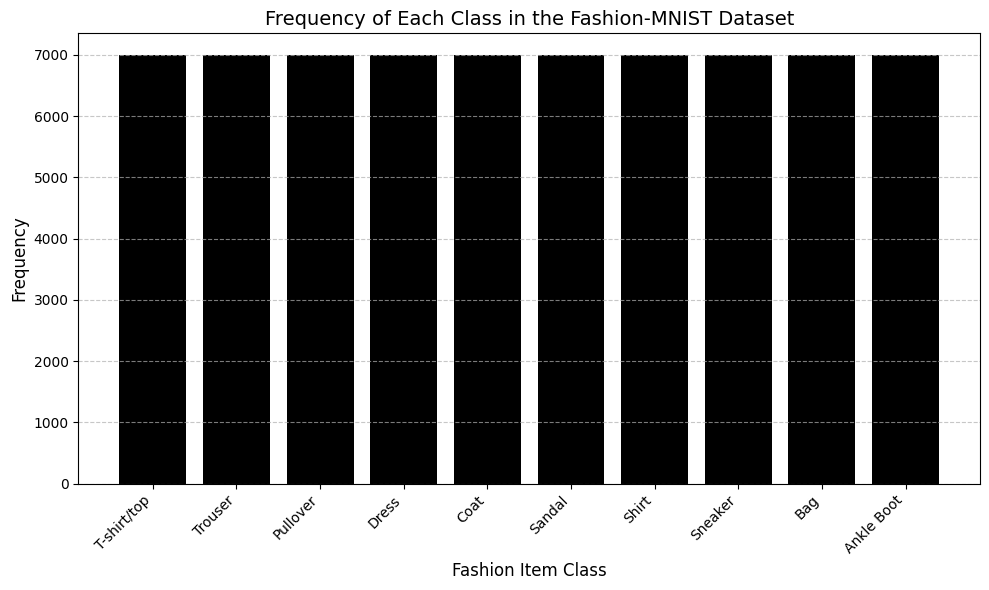

In [7]:
class_labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle Boot"
]

# Count the frequency of each class label
unique_labels, counts = np.unique(y, return_counts=True)

# Display the frequencies in a table format
print("Frequency of each class:")
for label, count in zip(unique_labels, counts):
    print(f"{class_labels[int(label)]}: {count} samples")

# Visualize the frequency of class labels using a bar plot
plt.figure(figsize=(10, 6))
plt.bar(class_labels, counts, color='black')
plt.xlabel('Fashion Item Class', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Frequency of Each Class in the Fashion-MNIST Dataset', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


    1.6.a, b)

In [1]:
from sklearn.datasets import fetch_openml
import numpy as np
from sklearn.manifold import TSNE

mnist = fetch_openml('Fashion-MNIST', version=1, as_frame=False)
X, y = mnist.data, mnist.target.astype(int)

def sample_per_class(X, y, samples_per_class=100):
    sampled_data = []
    sampled_labels = []
    classes = np.unique(y)  # Digit classes (0–9)

    for cls in classes:
        cls_indices = np.where(y == cls)[0]  # Get indices for class
        random_indices = np.random.choice(cls_indices, samples_per_class, replace=False)
        sampled_data.append(X[random_indices])
        sampled_labels.append(y[random_indices])

    return np.vstack(sampled_data), np.hstack(sampled_labels)

# Class label mapping (e.g., MNIST Fashion labels)
class_labels = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

# Sample the data
X_sampled, y_sampled = sample_per_class(X, y, samples_per_class=100)

# Apply t-SNE for dimensionality reduction
tsne = TSNE(n_components=3, random_state=42, perplexity=30, max_iter=500)
X_tsne_3d = tsne.fit_transform(X_sampled)

2)Data Preparation
    2.1)

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Training set shape:", X_train.shape)
print("Validation set shape:", X_val.shape)
print("Test set shape:", X_test.shape)

Training set shape: (49000, 784)
Validation set shape: (10500, 784)
Test set shape: (10500, 784)


    2.2)

In [10]:

def preprocess_data(train_features, val_features, test_features, variance_ratio=0.90):

    scaler = MinMaxScaler()
    train_scaled = scaler.fit_transform(train_features)
    val_scaled = scaler.transform(val_features)
    test_scaled = scaler.transform(test_features)

    pca = PCA(n_components=variance_ratio)
    train_pca = pca.fit_transform(train_scaled)
    val_pca = pca.transform(val_scaled)
    test_pca = pca.transform(test_scaled)

    print(f"Number of Principal Components selected: {pca.n_components_}")
    print(f"Final dimension of the dataset: {train_pca.shape[1]}")

    return train_pca, val_pca, test_pca

3) Implementing the Classifier

In [12]:
def knn_predict(train_features, train_labels, evaluate_features, k):

  num_eval = evaluate_features.shape[0]
  predicted_labels = np.zeros(num_eval)
  epsilon = 1e-10  # Small constant to prevent division by zero

  for i in range(num_eval):
    eval_point = evaluate_features[i, :]
    distances = np.linalg.norm(train_features - eval_point, axis=1)

    # Get indices of k nearest neighbors
    nearest_indices = np.argsort(distances)[:k]

    # Get labels and distances of k nearest neighbors
    nearest_labels = train_labels[nearest_indices]
    nearest_distances = distances[nearest_indices]

    # Calculate weights for each neighbor
    weights = 1 / (nearest_distances + epsilon)

    # Calculate weighted votes for each label
    unique_labels, unique_label_indices = np.unique(nearest_labels, return_inverse=True)
    weighted_votes = np.bincount(unique_label_indices, weights=weights)

    # Handle ties: Choose label with the smallest average distance
    max_votes = np.max(weighted_votes)
    max_vote_indices = np.where(weighted_votes == max_votes)[0]
    if len(max_vote_indices) > 1:
      avg_distances = []
      for label_index in max_vote_indices:
        label = unique_labels[label_index]
        label_distances = nearest_distances[nearest_labels == label]
        avg_distances.append(np.mean(label_distances))
      predicted_labels[i] = unique_labels[max_vote_indices[np.argmin(avg_distances)]]
    else:
      predicted_labels[i] = unique_labels[max_vote_indices[0]]

  return predicted_labels

4) Hyperparameter Tuning

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

def tune_knn_pca(train_features, train_labels, val_features, val_labels, pca_ratios, k_values):
    results = {}  # Dictionary to store accuracy for each (variance_ratio, k)

    for variance_ratio in pca_ratios:
        print(f"Processing PCA Variance Ratio: {variance_ratio:.2f}")

        # Preprocess data with the current PCA variance ratio
        X_train_pca, X_val_pca, _ = preprocess_data(train_features, val_features, val_features, variance_ratio)

        for k in k_values:
            # Initialize and run the KNN classifier
            y_val_pred = knn_predict(X_train_pca, train_labels, X_val_pca, k=k)

            # Calculate accuracy on the validation set
            accuracy = accuracy_score(val_labels, y_val_pred)
            results[(variance_ratio, k)] = accuracy
            print(f"    k={k}, Accuracy={accuracy:.4f}")

    return results


# Plot the results as a heatmap or grid
def plot_tuning_results(results, pca_ratios, k_values):
    accuracies = np.zeros((len(pca_ratios), len(k_values)))

    # Fill accuracy grid
    for i, vr in enumerate(pca_ratios):
        for j, k in enumerate(k_values):
            accuracies[i, j] = results[(vr, k)]

    # Create heatmap
    plt.figure(figsize=(10, 6))
    plt.imshow(accuracies, interpolation='nearest', cmap='viridis', aspect='auto')
    plt.colorbar(label='Validation Accuracy')

    plt.xticks(ticks=np.arange(len(k_values)), labels=k_values)
    plt.yticks(ticks=np.arange(len(pca_ratios)), labels=[f"{vr:.2f}" for vr in pca_ratios])
    plt.xlabel('Number of Neighbors (k)')
    plt.ylabel('PCA Variance Ratio')
    plt.title('Impact of Hyperparameters on Validation Accuracy')
    plt.show()


# Hyperparameter Ranges
pca_variance_ratios = [0.80, 0.85, 0.90, 0.95]
k_values = [1, 3, 5, 7, 9, 11]

# Run the tuning process
results = tune_knn_pca(X_train, y_train, X_val, y_val, pca_variance_ratios, k_values)

# Plot the results
plot_tuning_r

Processing PCA Variance Ratio: 0.80
Number of Principal Components selected: 24
Final dimension of the dataset: 24
    k=1, Accuracy=0.8272
    k=3, Accuracy=0.8450
    k=5, Accuracy=0.8509
    k=7, Accuracy=0.8514
    k=9, Accuracy=0.8522
    k=11, Accuracy=0.8531
Processing PCA Variance Ratio: 0.85
Number of Principal Components selected: 43
Final dimension of the dataset: 43
    k=1, Accuracy=0.8386
    k=3, Accuracy=0.8557
    k=5, Accuracy=0.8586
    k=7, Accuracy=0.8605
    k=9, Accuracy=0.8598
    k=11, Accuracy=0.8588
Processing PCA Variance Ratio: 0.90
Number of Principal Components selected: 84
Final dimension of the dataset: 84
    k=1, Accuracy=0.8463
    k=3, Accuracy=0.8620
    k=5, Accuracy=0.8624
    k=7, Accuracy=0.8654
    k=9, Accuracy=0.8626
    k=11, Accuracy=0.8632
Processing PCA Variance Ratio: 0.95
Number of Principal Components selected: 188
Final dimension of the dataset: 188
    k=1, Accuracy=0.8505
    k=3, Accuracy=0.8632
    k=5, Accuracy=0.8659


5) Final Evaluation

In [1]:
X_train_pca, X_val_pca, X_test_pca = preprocess_data(X_train, X_val, X_test, variance_ratio=0.95)
k = 5
y_test_pred = knn_predict(X_train_pca, y_train, X_test_pca, k=k)

# 3. Calculate Per-Class Metrics
classes = np.unique(y_test)
class_metrics = {}

for cls in classes:
    # Convert to one-vs-all format
    y_test_binary = (y_test == cls).astype(int)
    y_pred_binary = (y_test_pred == cls).astype(int)

    precision = precision_score(y_test_binary, y_pred_binary, zero_division=0)
    recall = recall_score(y_test_binary, y_pred_binary, zero_division=0)
    f1 = f1_score(y_test_binary, y_pred_binary, zero_division=0)
    auc = roc_auc_score(y_test_binary, y_pred_binary)

    class_metrics[cls] = {
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "AUC": auc
    }

# Display per-class metrics
print("Per Class Metrics:")
for cls, metrics in class_metrics.items():
    print(f"Class {cls}: {metrics}")

# 4. Generate and present ROC Curves for selected classes
selected_classes = [0, 6, 9]
plt.figure(figsize=(10, 8))
for cls in selected_classes:
    y_test_binary = (y_test == cls).astype(int)
    y_pred_binary = (y_test_pred == cls).astype(int)
    fpr, tpr, _ = roc_curve(y_test_binary, y_pred_binary)
    plt.plot(fpr, tpr, label=f"Class {cls} (AUC={class_metrics[cls]['AUC']:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid()
plt.show()

# 5. Calculate Overall Metrics
accuracy = accuracy_score(y_test, y_test_pred)
conf_matrix = confusion_matrix(y_test, y_test_pred)

# Macro metrics
macro_precision = np.mean([metrics["Precision"] for metrics in class_metrics.values()])
macro_recall = np.mean([metrics["Recall"] for metrics in class_metrics.values()])
macro_f1 = np.mean([metrics["F1 Score"] for metrics in class_metrics.values()])
macro_auc = np.mean([metrics["AUC"] for metrics in class_metrics.values()])

# Display Overall Metrics
print("\nOverall Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")
print(f"Macro AUC: {macro_auc:.4f}")

# 6. Visualize the Confusion Matrix
plt.figure(figsize=(12, 8))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

NameError: name 'preprocess_data' is not defined